In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import ks_2samp
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

warnings.filterwarnings('ignore')

In [2]:
data_2013 = pd.read_csv('data/fraud_2013.csv')
data_2023 = pd.read_csv('data/fraud_2023.csv')

data_2013

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
284802,172786.0,-11.881118,10.071785,-9.834783,-2.066656,-5.364473,-2.606837,-4.918215,7.305334,1.914428,...,0.213454,0.111864,1.014480,-0.509348,1.436807,0.250034,0.943651,0.823731,0.77,0
284803,172787.0,-0.732789,-0.055080,2.035030,-0.738589,0.868229,1.058415,0.024330,0.294869,0.584800,...,0.214205,0.924384,0.012463,-1.016226,-0.606624,-0.395255,0.068472,-0.053527,24.79,0
284804,172788.0,1.919565,-0.301254,-3.249640,-0.557828,2.630515,3.031260,-0.296827,0.708417,0.432454,...,0.232045,0.578229,-0.037501,0.640134,0.265745,-0.087371,0.004455,-0.026561,67.88,0
284805,172788.0,-0.240440,0.530483,0.702510,0.689799,-0.377961,0.623708,-0.686180,0.679145,0.392087,...,0.265245,0.800049,-0.163298,0.123205,-0.569159,0.546668,0.108821,0.104533,10.00,0


=== fraud_2013 ===
           n  prop_dif_media  dif_bonf_media  D_max_medio  D_medio
frac                                                              
0.01    2848          0.0450            0.10       0.0280   0.0159
0.02    5696          0.0533            0.00       0.0194   0.0113
0.05   14241          0.0317            0.00       0.0121   0.0070
0.10   28481          0.0250            0.05       0.0085   0.0049
0.20   56961          0.0067            0.00       0.0055   0.0032
0.30   85442          0.0017            0.00       0.0043   0.0025
0.50  142404          0.0000            0.00       0.0027   0.0016

=== fraud_2023 ===
           n  prop_dif_media  dif_bonf_media  D_max_medio  D_medio
frac                                                              
0.01    5686          0.0310             0.1       0.0195   0.0107
0.02   11372          0.0293             0.0       0.0130   0.0076
0.05   28432          0.0207             0.0       0.0081   0.0047
0.10   56864          0

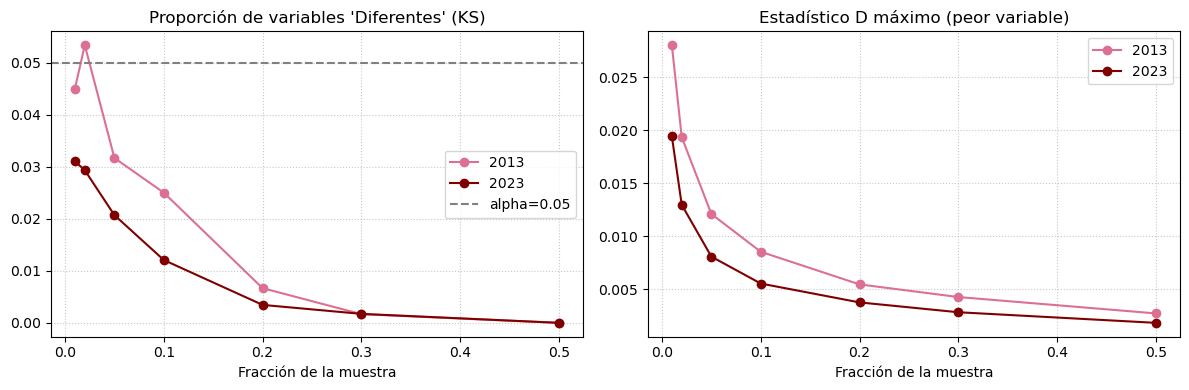

   Variable         D   p-value  Diferente (sin corregir)  \
19      V19  0.007016  0.155539                     False   
17      V17  0.007014  0.155732                     False   
1        V1  0.006528  0.218848                     False   
26      V26  0.006156  0.279088                     False   
27      V27  0.006036  0.300934                     False   
5        V5  0.005736  0.360358                     False   
20      V20  0.005693  0.369520                     False   
4        V4  0.005503  0.411663                     False   
13      V13  0.005455  0.422565                     False   
22      V22  0.005363  0.444220                     False   
8        V8  0.005335  0.450936                     False   
21      V21  0.005306  0.457986                     False   
25      V25  0.005205  0.482846                     False   
12      V12  0.004908  0.559237                     False   
28      V28  0.004902  0.560674                     False   
10      V10  0.004761  0

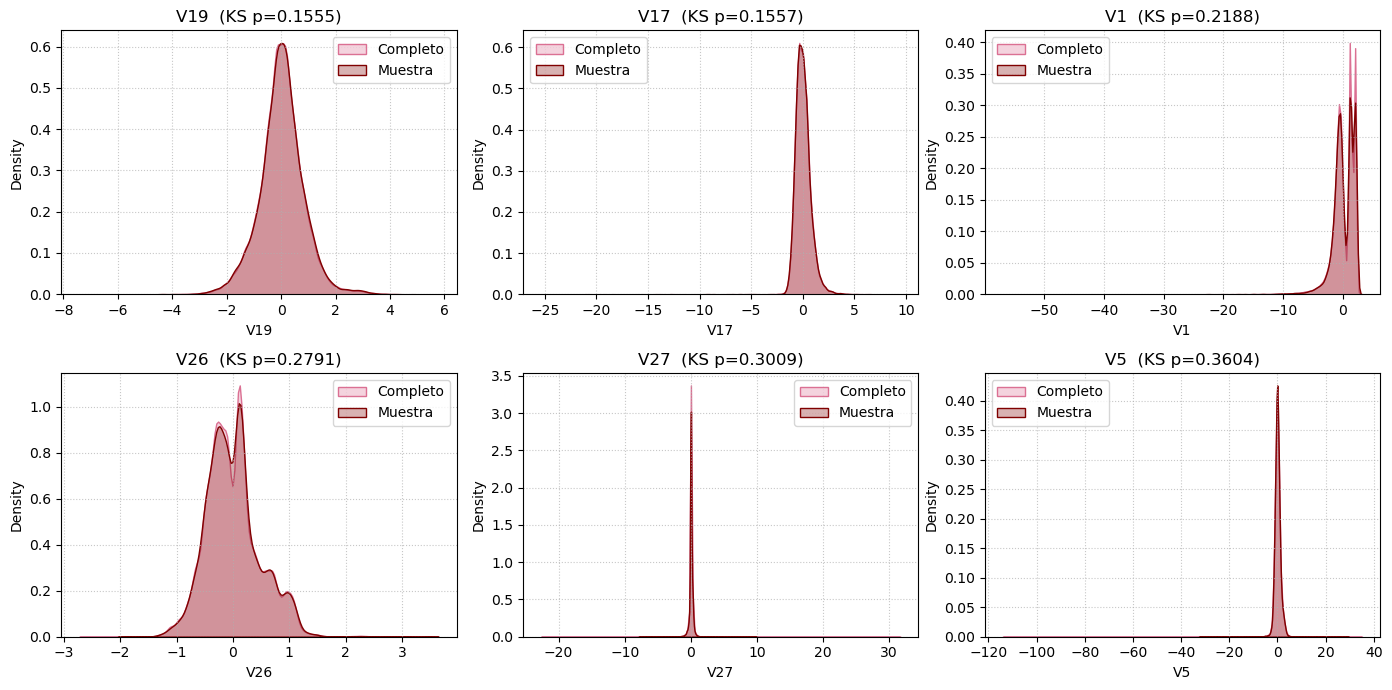

   Variable         D   p-value  Diferente (sin corregir)  \
28   Amount  0.004798  0.184278                     False   
21      V22  0.004564  0.231002                     False   
16      V17  0.004433  0.260833                     False   
24      V25  0.004305  0.292476                     False   
19      V20  0.003985  0.383480                     False   
12      V13  0.003608  0.510172                     False   
14      V15  0.003551  0.531105                     False   
26      V27  0.003394  0.589539                     False   
4        V5  0.003379  0.595235                     False   
0        V1  0.003373  0.597776                     False   
25      V26  0.003334  0.612505                     False   
18      V19  0.003161  0.678536                     False   
17      V18  0.002996  0.741006                     False   
9       V10  0.002991  0.742808                     False   
7        V8  0.002826  0.802255                     False   
3        V4  0.002814  0

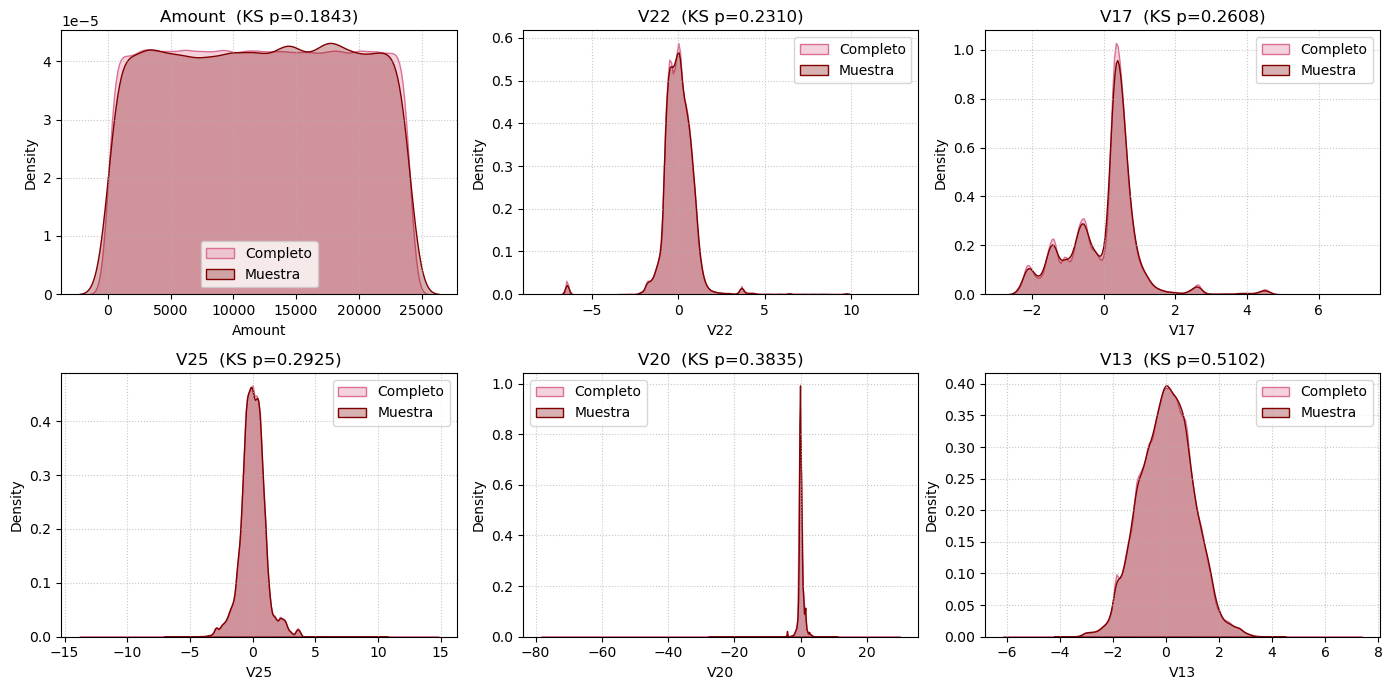

In [3]:
alpha = 0.05

def comparar(completo, muestra, cols, alpha=alpha):
    """KS por variable. Devuelve p-value y estadístico D de cada una."""
    filas = []
    for col in cols:
        D, p = ks_2samp(completo[col].dropna(), muestra[col].dropna())
        filas.append({'Variable': col, 'D': D, 'p-value': p})
    df = pd.DataFrame(filas)
    # Bonferroni: con ~30 variables, a alpha=0.05 esperas ~1-2 falsos positivos por azar
    df['Diferente (sin corregir)'] = df['p-value'] < alpha
    df['Diferente (Bonferroni)'] = df['p-value'] < alpha / len(cols)
    return df

def evaluar_recortes(data_original, fracciones, cols, n_rep=20, estratificar=None):
    resumen = []
    for frac in fracciones:
        for seed in range(n_rep):
            if estratificar and estratificar in data_original.columns:
                muestra = (data_original.groupby(estratificar, group_keys=False)
                           .sample(frac=frac, random_state=seed))
            else:
                muestra = data_original.sample(frac=frac, random_state=seed)
            r = comparar(data_original, muestra, cols)
            resumen.append({
                'frac': frac,
                'n': len(muestra),
                'seed': seed,
                'prop_dif': r['Diferente (sin corregir)'].mean(),
                'n_dif_bonf': r['Diferente (Bonferroni)'].sum(),
                'D_max': r['D'].max(),
                'D_medio': r['D'].mean(),
            })
    return pd.DataFrame(resumen)

excluir = ['Class', 'id']
cols_2013 = [c for c in data_2013.columns if c not in excluir]
cols_2023 = [c for c in data_2023.columns if c not in excluir]

fracciones = [0.01, 0.02, 0.05, 0.10, 0.20, 0.30, 0.50]

res_2013 = evaluar_recortes(data_2013, fracciones, cols_2013, n_rep=20, estratificar='Class')
res_2023 = evaluar_recortes(data_2023, fracciones, cols_2023, n_rep=20, estratificar='Class')

def resumir(res):
    return (res.groupby('frac')
              .agg(n=('n', 'first'),
                   prop_dif_media=('prop_dif', 'mean'),      # ideal: ~ alpha (0.05)
                   dif_bonf_media=('n_dif_bonf', 'mean'),    # ideal: ~ 0
                   D_max_medio=('D_max', 'mean'),
                   D_medio=('D_medio', 'mean'))
              .round(4))

print("=== fraud_2013 ===");  print(resumir(res_2013))
print("\n=== fraud_2023 ===");  print(resumir(res_2023))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for res, nombre, color in [(res_2013, '2013', 'palevioletred'), (res_2023, '2023', 'maroon')]:
    g = res.groupby('frac')
    axes[0].plot(g['prop_dif'].mean().index, g['prop_dif'].mean(), marker='o', label=nombre, color=color)
    axes[1].plot(g['D_max'].mean().index, g['D_max'].mean(), marker='o', label=nombre, color=color)

axes[0].axhline(alpha, ls='--', color='gray', label=f'alpha={alpha}')
axes[0].set_title("Proporción de variables 'Diferentes' (KS)")
axes[1].set_title("Estadístico D máximo (peor variable)")
for ax in axes:
    ax.set_xlabel("Fracción de la muestra"); ax.grid(linestyle=':', alpha=0.7); ax.legend()
plt.tight_layout(); plt.show()

def detalle(data_original, frac, cols, seed=0, estratificar='Class'):
    muestra = (data_original.groupby(estratificar, group_keys=False).sample(frac=frac, random_state=seed)
               if estratificar in data_original.columns
               else data_original.sample(frac=frac, random_state=seed))
    r = comparar(data_original, muestra, cols).sort_values('p-value')
    print(r)

    peores = r['Variable'].head(6).tolist() 
    fig, axes = plt.subplots(2, 3, figsize=(14, 7))
    for ax, col in zip(axes.ravel(), peores):
        sns.kdeplot(data_original[col], ax=ax, label='Completo', fill=True, alpha=0.3, color='palevioletred')
        sns.kdeplot(muestra[col], ax=ax, label='Muestra', fill=True, alpha=0.3, color='maroon')
        p = r.loc[r['Variable'] == col, 'p-value'].iloc[0]
        ax.set_title(f"{col}  (KS p={p:.4f})"); ax.grid(linestyle=':', alpha=0.7); ax.legend()
    plt.tight_layout(); plt.show()
    return muestra

muestra_2013 = detalle(data_2013, 0.10, cols_2013)
muestra_2023 = detalle(data_2023, 0.10, cols_2023)